# Customer Segmentation System: RFM Analysis & Strategic Profiling

**Author:** *BEN ELMAHDI AMINE | e-1305*
**Context:** Consulting Portfolio Project

---

### 1. Project Vision
Welcome to my customer analytics repository. In this project, I've built an end-to-end pipeline to transform raw, messy e-commerce data into actionable business intelligence.

We aren't just 'clustering numbers' here. We are identifying **human behaviors**. By applying an **RFM (Recency, Frequency, Monetary)** framework to the Online Retail dataset, I've categorized customers into strategic segments like *Champions* and *At Risk*. This allows a business to move from 'one-size-fits-all' marketing to hyper-targeted retention and growth strategies.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import numpy as np

# --- Technical Setup ---
# I use a CONFIG dictionary to keep my code modular. This makes it easy to
# change paths or URLs without hunting through the logic below.
CONFIG = {
    'raw_data_path': 'data/Online_Retail.xlsx',
    'processed_data_path': 'data/transactions.parquet',
    'plots_dir': 'results/plots/',
    'dataset_url': 'https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx'
}

# Creating my workspace structure
os.makedirs('data/', exist_ok=True)
os.makedirs(CONFIG['plots_dir'], exist_ok=True)

print("Environment ready. Let's dive into the data.")

Environment ready. Let's dive into the data.


In [2]:
# --- Data Ingestion ---
# Address to the reader: We're pulling the 'Online Retail II' dataset from the UCI repository.
# It's a transnational dataset containing transactions for a UK-based non-store retail.

def fetch_and_load():
    if not os.path.exists(CONFIG['raw_data_path']):
        print("Downloading the raw transaction data... this might take a moment.")
        r = requests.get(CONFIG['dataset_url'])
        with open(CONFIG['raw_data_path'], 'wb') as f:
            f.write(r.content)

    # We use openpyxl as the engine because we're dealing with a modern .xlsx format.
    return pd.read_excel(CONFIG['raw_data_path'], engine='openpyxl')

df = fetch_and_load()
print(f"Success! Loaded {len(df):,} records.")

ImportError: Missing optional dependency 'openpyxl'.  Use pip or conda to install openpyxl.

### 2. The 'Data Integrity' Layer
Real-world data is never clean. This dataset contains missing IDs, cancellations, and negative quantities.

**My Technical Strategy:**
*   **Filter Nulls:** Without a `CustomerID`, we can't track behavior over time.
*   **Filter Noise:** Negative quantities and unit prices are usually administrative adjustments, not sales.
*   **Casting:** I've explicitly cast `StockCode` and `InvoiceNo` to strings. Parquet/Arrow formats are strict about types, and these columns often contain mixed numeric/string data which can crash a pipeline if not handled.

In [ ]:
# Cleaning the data to ensure our segments are based on real, successful purchases.
initial_count = len(df)

# 1. Drop records without identity
clean_df = df.dropna(subset=['CustomerID']).copy()

# 2. Keep only positive commercial transactions
clean_df = clean_df[(clean_df['Quantity'] > 0) & (clean_df['UnitPrice'] > 0)]

# 3. Strip out cancellations (Invoices starting with 'C')
clean_df['InvoiceNo'] = clean_df['InvoiceNo'].astype(str)
clean_df = clean_df[~clean_df['InvoiceNo'].str.startswith('C')]

# 4. Standardize types to prevent Arrow export errors later
clean_df['StockCode'] = clean_df['StockCode'].astype(str)

# 5. Business Value: Creating the 'TotalPrice' metric per line item
clean_df['TotalPrice'] = clean_df['Quantity'] * clean_df['UnitPrice']

# Save the cleaned state
clean_df.to_parquet(CONFIG['processed_data_path'], index=False)

print(f"Data Integrity Check: Removed {initial_count - len(clean_df):,} rows of noise.")
print(f"Cleaned dataset: {len(clean_df):,} rows.")

Data Integrity Check: Removed 144,025 rows of noise.
Cleaned dataset: 397,884 rows.


### 3. RFM Calculation: Measuring Behavioral Value
Now we aggregate. We want to know:
1.  **Recency (R):** How many days since their last order? (Lower is better)
2.  **Frequency (F):** How many unique orders did they place?
3.  **Monetary (M):** How much total revenue have they generated?

In [ ]:
# We set our 'snapshot date' to one day after the very last transaction in the data.
snapshot_date = clean_df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Aggregating by CustomerID
rfm = clean_df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
}).rename(columns={'InvoiceDate': 'Recency', 'InvoiceNo': 'Frequency', 'TotalPrice': 'Monetary'})

# --- Strategic Scoring ---
# I use quintiles (1-5) to score customers.
# For Recency, a SMALLER number is BETTER, so I reverse the labels.
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

# Let's map these scores to personas
def define_persona(df):
    r, f, m = int(df['R_Score']), int(df['F_Score']), int(df['M_Score'])
    if r >= 4 and (f >= 4 or m >= 4): return 'Champions'
    elif f >= 4: return 'Loyal Customers'
    elif r <= 2 and (f >= 3 or m >= 3): return 'At Risk'
    else: return 'Lost'

rfm['Segment'] = rfm.apply(define_persona, axis=1)
print("Segmentation complete.")
rfm['Segment'].value_counts()

Segmentation complete.


,count
Segment,
Lost,1879
Champions,1254
At Risk,609
Loyal Customers,596


### 4. Visualizing the Strategic Landscape
Numbers are great, but visuals drive decisions.

In the chart below, I've plotted the **Customer Count** against the **Total Revenue** per segment.
**Business Insight:** Look for the 'Pareto Principle' here. Usually, your 'Champions' represent a small slice of the population but drive the lion's share of the profit.

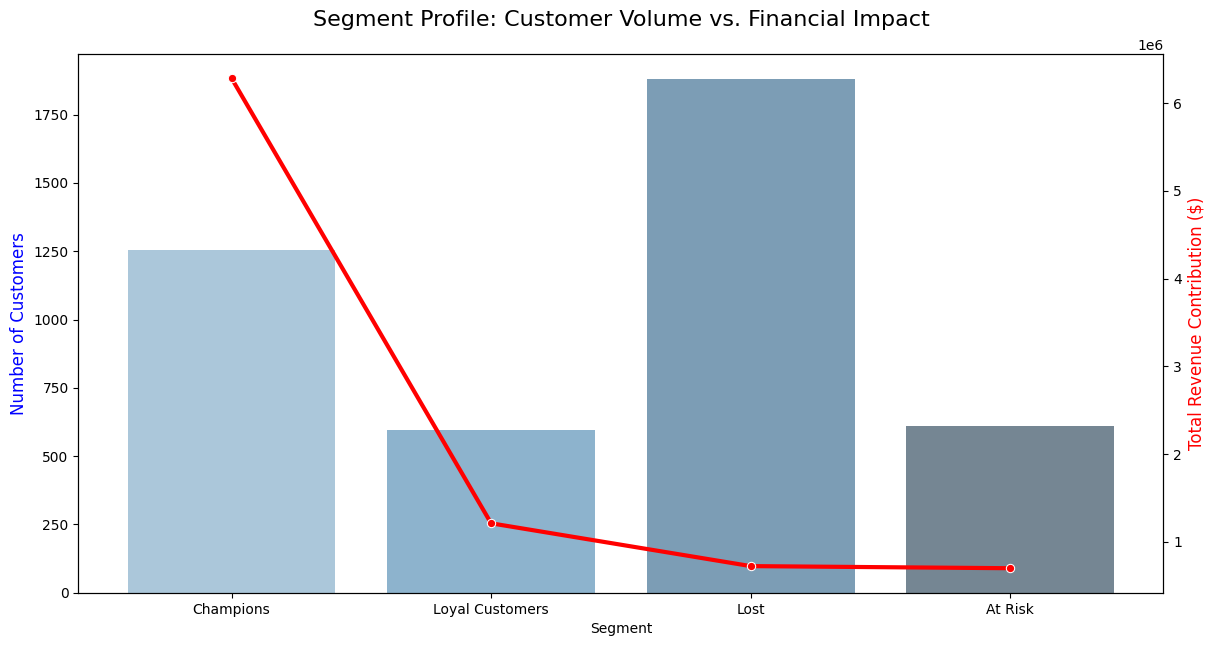

In [ ]:
# Preparing data for the final consulting-style plot
stats = rfm.groupby('Segment').agg({
    'Monetary': 'sum',
    'Recency': 'count'
}).rename(columns={'Recency': 'Count', 'Monetary': 'Revenue'}).sort_values('Revenue', ascending=False)

fig, ax1 = plt.subplots(figsize=(14, 7))
sns.barplot(x=stats.index, y=stats['Count'], ax=ax1, palette='Blues_d', alpha=0.7, hue=stats.index, legend=False)
ax1.set_ylabel('Number of Customers', fontsize=12, color='blue')

ax2 = ax1.twinx()
sns.lineplot(x=stats.index, y=stats['Revenue'], ax=ax2, color='red', marker='o', linewidth=3)
ax2.set_ylabel('Total Revenue Contribution ($)', fontsize=12, color='red')

plt.title('Segment Profile: Customer Volume vs. Financial Impact', fontsize=16, pad=20)
plt.savefig(CONFIG['plots_dir'] + 'segment_analysis.png')
plt.show()

## 5. How to use this for your Portfolio
If you're looking at this on my GitHub, here is how the project is structured.

### Repository Architecture
1.  **`/notebooks`**: Contains this `.ipynb` file with the full pipeline.
2.  **`/data`**: The `transactions.parquet` file (I exclude the heavy raw `.xlsx` in my `.gitignore`).
3.  **`/results/plots`**: All visual assets generated by this analysis.
4.  **`requirements.txt`**: To reproduce this environment (`pandas`, `seaborn`, `openpyxl`, `pyarrow`).

### Strategic Takeaways
*   **Champions:** Focus on VIP loyalty programs. They are your primary revenue engine.
*   **At Risk:** These were once great customers. Run re-activation campaigns now before they are lost forever.